# 04 · Did the Segment-Targeted Coupon Program Work?

**Design:** customers in the *Deal Seekers* and *New Potential* segments (notebook 03) were randomly split
on 2023-09-01 — **80% treatment** (received targeted coupons) and **20% holdout control** (no targeted coupons).

**Primary metric:** completed orders per customer, Sep 1 – Nov 30 (91 days).
**Secondary:** buyer rate, net GMV per customer (after discounts), discount cost.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

import db
import plot_style as ps

ps.apply()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
con = db.connect()
rng = np.random.default_rng(0)

In [2]:
pc = db.run(con, "05_coupon_program_results")
pc["buyer_post"] = (pc["orders_post"] > 0).astype(int)
pc["group"].value_counts()

group
treatment    2997
control       771
Name: count, dtype: int64

## 1. Balance check — were the groups comparable before launch?

In [3]:
cust = con.execute("SELECT * FROM customers").df().set_index("customer_id")
bal = pc.join(cust, on="customer_id")
pre = bal.groupby("group").agg(customers=("customer_id", "size"),
                               orders_pre=("orders_pre", "mean"),
                               gmv_pre=("gmv_pre", "mean"))
pre["share_new_potential_%"] = bal.groupby("group")["segment_at_launch"].apply(lambda s: (s == "New Potential").mean() * 100)
pre["share_tier1_2_%"] = bal.groupby("group")["city_tier"].apply(lambda s: s.isin(["Tier 1", "Tier 2"]).mean() * 100)
display(pre.round(2))
t = stats.ttest_ind(pc.loc[pc.group == "treatment", "orders_pre"], pc.loc[pc.group == "control", "orders_pre"],
                    equal_var=False)
print(f"Pre-period orders difference: p = {t.pvalue:.3f}")

,customers,orders_pre,gmv_pre,share_new_potential_%,share_tier1_2_%
group,,,,,
control,771,1.24,90.11,21.40,48.77
treatment,2997,1.14,81.67,24.26,45.68


Pre-period orders difference: p = 0.043


Segment mix and city tiers are balanced. Pre-period orders differ slightly by chance, so besides the simple
post-period comparison we also run a **difference-in-differences** model that nets out any pre-existing gap.

## 2. Results (Sep 1 – Nov 30)

In [4]:
def boot_ci(t, c, n=5000):
    t, c = np.asarray(t), np.asarray(c)
    diffs = [rng.choice(t, len(t)).mean() / rng.choice(c, len(c)).mean() - 1 for _ in range(n)]
    return np.percentile(diffs, [2.5, 97.5]) * 100


rows = []
for metric, label in [("orders_post", "Orders per customer"), ("buyer_post", "Buyer rate"),
                      ("gmv_post", "Net GMV per customer (¥)"), ("discount_post", "Discount cost per customer (¥)")]:
    tr, ct = pc.loc[pc.group == "treatment", metric], pc.loc[pc.group == "control", metric]
    lo, hi = boot_ci(tr, ct)
    rows.append({"metric": label, "treatment": tr.mean(), "control": ct.mean(),
                 "lift_%": (tr.mean() / ct.mean() - 1) * 100, "95% CI low": lo, "95% CI high": hi,
                 "p_value (Welch t)": stats.ttest_ind(tr, ct, equal_var=False).pvalue})
results = pd.DataFrame(rows).set_index("metric")
results.round(3)

,treatment,control,lift_%,95% CI low,95% CI high,p_value (Welch t)
metric,,,,,,
Orders per customer,2.039,1.367,49.156,37.181,62.965,0.0
Buyer rate,0.755,0.664,13.655,7.828,20.265,0.0
Net GMV per customer (¥),157.199,115.157,36.508,23.421,51.426,0.0
Discount cost per customer (¥),24.557,12.453,97.193,77.792,119.810,0.0


## 3. Difference-in-differences
`orders ~ treated × post`, standard errors clustered by customer.

In [5]:
long = pd.concat([
    pc.assign(post=0, orders=pc["orders_pre"]),
    pc.assign(post=1, orders=pc["orders_post"]),
])[["customer_id", "group", "post", "orders"]]
long["treated"] = (long["group"] == "treatment").astype(int)
did = smf.ols("orders ~ treated * post", data=long).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(long["customer_id"])[0]})
print(did.summary().tables[1])
effect = did.params["treated:post"]
ci = did.conf_int().loc["treated:post"]
control_post = pc.loc[pc.group == "control", "orders_post"].mean()
print(f"\nDiD effect: {effect:+.2f} orders per customer (95% CI {ci[0]:+.2f} to {ci[1]:+.2f}), "
      f"= {effect / control_post:+.0%} vs. control post-period level")

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.2361      0.044     27.935      0.000       1.149       1.323
treated         -0.0993      0.049     -2.031      0.042      -0.195      -0.003
post             0.1310      0.061      2.140      0.032       0.011       0.251
treated:post     0.7712      0.071     10.936      0.000       0.633       0.909

DiD effect: +0.77 orders per customer (95% CI +0.63 to +0.91), = +56% vs. control post-period level


## 4. Weekly view

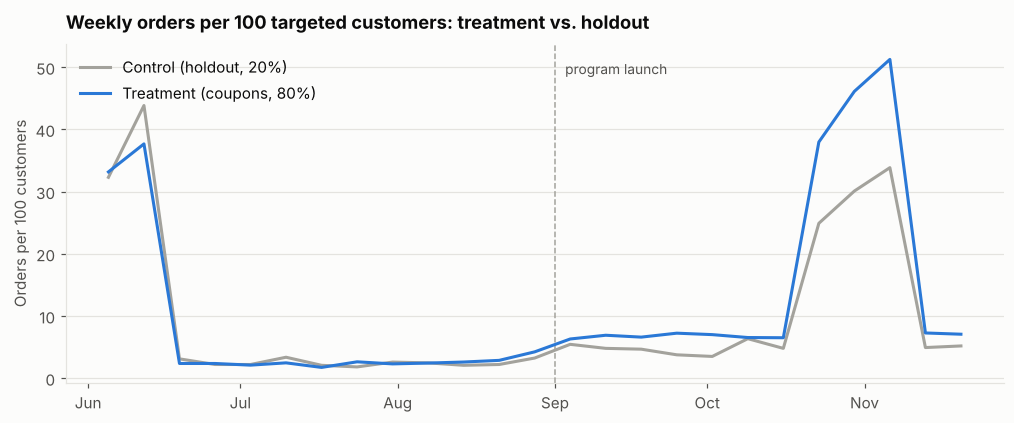

In [6]:
weekly = con.execute("""
    SELECT DATE_TRUNC('week', o.order_date) AS week, cp."group", COUNT(*) AS orders
    FROM orders o JOIN coupon_program cp USING (customer_id)
    WHERE o.order_status = 'completed' AND o.order_date BETWEEN DATE '2023-06-05' AND DATE '2023-11-26'
    GROUP BY 1, 2
""").df()
sizes = pc["group"].value_counts()
weekly["orders_per_100"] = weekly["orders"] / weekly["group"].map(sizes) * 100
w = weekly.pivot(index="week", columns="group", values="orders_per_100").sort_index()

fig, ax = plt.subplots(figsize=(11, 4))
ax.axvline(pd.Timestamp("2023-09-01"), color=ps.CONTEXT, lw=1, ls="--")
ax.plot(w.index, w["control"], color=ps.CONTEXT, label="Control (holdout, 20%)")
ax.plot(w.index, w["treatment"], color=ps.BLUE, label="Treatment (coupons, 80%)")
ax.text(pd.Timestamp("2023-09-03"), ax.get_ylim()[1] * 0.95, "program launch", color=ps.TEXT_2, fontsize=9, va="top")
ax.set_ylabel("Orders per 100 customers")
ax.set_title("Weekly orders per 100 targeted customers: treatment vs. holdout")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper left")
ps.save(fig, "04_weekly_treatment_vs_control")

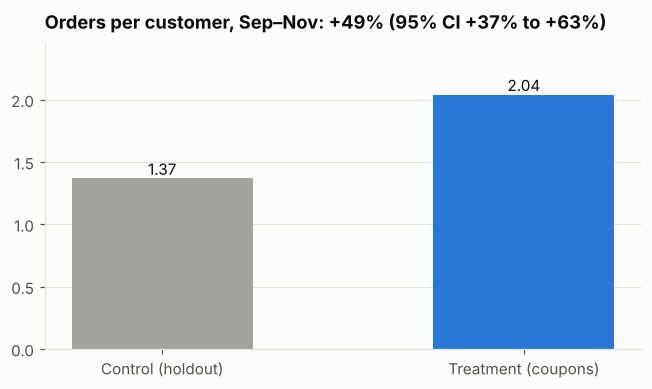

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
cmp = results.loc[["Orders per customer"], ["control", "treatment"]].T
ax.bar(["Control (holdout)", "Treatment (coupons)"], cmp["Orders per customer"], color=[ps.CONTEXT, ps.BLUE], width=0.5)
for i, v in enumerate(cmp["Orders per customer"]):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center", color=ps.TEXT)
r = results.loc["Orders per customer"]
ax.set_title(f"Orders per customer, Sep–Nov: +{r['lift_%']:.0f}% "
             f"(95% CI +{r['95% CI low']:.0f}% to +{r['95% CI high']:.0f}%)")
ax.set_ylim(0, cmp["Orders per customer"].max() * 1.2)
ps.save(fig, "04_orders_lift")

## 5. Lift by segment

In [8]:
seg_rows = []
for s, g in pc.groupby("segment_at_launch"):
    tr, ct = g.loc[g.group == "treatment", "orders_post"], g.loc[g.group == "control", "orders_post"]
    lo, hi = boot_ci(tr, ct, 3000)
    seg_rows.append({"segment": s, "n_treatment": len(tr), "n_control": len(ct),
                     "orders_treatment": tr.mean(), "orders_control": ct.mean(),
                     "lift_%": (tr.mean() / ct.mean() - 1) * 100, "95% CI low": lo, "95% CI high": hi})
pd.DataFrame(seg_rows).set_index("segment").round(2)

,n_treatment,n_control,orders_treatment,orders_control,lift_%,95% CI low,95% CI high
segment,,,,,,,
Deal Seekers,2270,606,2.14,1.42,50.90,38.10,65.30
New Potential,727,165,1.73,1.19,46.02,21.82,82.12


## 6. Is it profitable?
Net GMV already subtracts all discounts. The incremental net GMV is the extra revenue the program created
after paying for the coupons.

In [9]:
n_treated = sizes["treatment"]
inc_orders = (results.loc["Orders per customer", "treatment"] - results.loc["Orders per customer", "control"]) * n_treated
inc_gmv = (results.loc["Net GMV per customer (¥)", "treatment"] - results.loc["Net GMV per customer (¥)", "control"]) * n_treated
extra_discount = (results.loc["Discount cost per customer (¥)", "treatment"] - results.loc["Discount cost per customer (¥)", "control"]) * n_treated
print(f"Treated customers:          {n_treated:,}")
print(f"Incremental orders:         {inc_orders:,.0f}")
print(f"Incremental net GMV:        ¥{inc_gmv:,.0f}")
print(f"Extra discount spent:       ¥{extra_discount:,.0f}")
print(f"Net GMV per ¥1 of extra discount: ¥{inc_gmv / extra_discount:.2f}")

Treated customers:          2,997
Incremental orders:         2,014
Incremental net GMV:        ¥125,999
Extra discount spent:       ¥36,276
Net GMV per ¥1 of extra discount: ¥3.47


## Conclusion
- The targeted coupon program **increased orders per customer by roughly half** versus a randomized holdout,
  with a confidence interval well above zero; the DiD estimate that nets out the small pre-period gap agrees.
- The lift holds in **both target segments**, so the segmentation picked responsive customers.
- The program is **net-revenue positive**: incremental net GMV is several times the extra discount spend.
- **Next steps:** roll out to all Deal Seekers / New Potential customers while keeping a small permanent
  holdout to keep measuring; test a non-coupon intervention for Window Shoppers.